# CANNY PROCESSING

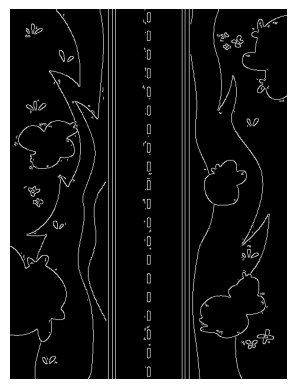

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

img = cv.imread("road2.jpg")
assert img is not None, "Không đọc được road2.jpg (kiểm tra đường dẫn)"
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

t_lower, t_upper, aperture_size, L2Gradient = 100, 200, 5, True
edges = cv.Canny(gray, t_lower, t_upper, apertureSize=aperture_size, L2gradient=L2Gradient)
plt.imshow(edges, cmap="gray"); plt.axis("off"); plt.show()

## Gradient (Sobel trên bản đồ cạnh, như cách làm cũ)
`grad_dir = arctan2(gy, gx)` dùng cho bỏ phiếu theo hướng gradient. Chỗ Sobel = 0 (cạnh cô lập) thì không có hướng -> `NaN` -> hàm Hough sẽ bỏ phiếu mọi theta.

(626, 470)


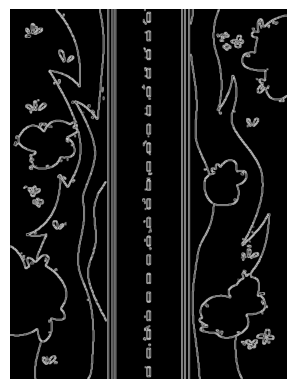

In [2]:
grad_x = cv.Sobel(edges, cv.CV_64F, 1, 0, ksize=3)
grad_y = cv.Sobel(edges, cv.CV_64F, 0, 1, ksize=3)
magnitude = cv.magnitude(grad_x, grad_y)

grad_dir = np.arctan2(grad_y, grad_x)          # radian, (-pi, pi]
grad_dir[magnitude == 0] = np.nan              # không có hướng

magnitude_norm = cv.normalize(magnitude, None, 0, 255, cv.NORM_MINMAX, dtype=cv.CV_8U)
print(magnitude_norm.shape)
plt.imshow(magnitude_norm, cmap="gray"); plt.axis("off"); plt.show()

# Hough transform
## Các hàm (numpy + convolve2d của nhóm)

In [3]:
import numpy as np

# ---- Dùng convolve2d của nhóm (Phần A). Đổi đường dẫn import cho đúng. ----
try:
    from partA import convolve2d          # giả định: convolve2d(img, kernel, mode='same')
except ImportError:                        # fallback để file chạy độc lập khi test
    def convolve2d(img, kernel, mode="same"):
        kh, kw = kernel.shape
        ph, pw = kh // 2, kw // 2
        P = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="constant")
        K = kernel[::-1, ::-1]
        out = np.zeros(img.shape, float)
        for i in range(kh):
            for j in range(kw):
                out += K[i, j] * P[i:i + img.shape[0], j:j + img.shape[1]]
        return out


def _gaussian_kernel(sigma):
    r = max(1, int(np.ceil(3 * sigma)))
    x = np.arange(-r, r + 1)
    g = np.exp(-x ** 2 / (2 * sigma ** 2))
    g /= g.sum()
    return np.outer(g, g)


def _local_max(A, r):
    """Max trong cửa sổ (2r+1)x(2r+1), thay cho scipy.ndimage.maximum_filter."""
    P = np.pad(A, r, mode="constant", constant_values=-np.inf)
    H, W = A.shape
    out = np.full(A.shape, -np.inf)
    for dy in range(2 * r + 1):
        for dx in range(2 * r + 1):
            np.maximum(out, P[dy:dy + H, dx:dx + W], out=out)
    return out


# ----------------------------------------------------------------------------
def hough_accumulate(edges, theta_range, rho_range, n_theta, n_rho,
                     grad_dir=None, delta_deg=None):
    """Bỏ phiếu vào mảng tích lũy. Nếu grad_dir khác None, chỉ bỏ phiếu
    trong dải +/- delta_deg quanh hướng gradient.
    Trả về (A, thetas, rhos)."""
    thetas = np.linspace(theta_range[0], theta_range[1], n_theta)
    rhos = np.linspace(rho_range[0], rho_range[1], n_rho)
    d_rho = (rho_range[1] - rho_range[0]) / max(n_rho - 1, 1)
    cos_t, sin_t = np.cos(thetas), np.sin(thetas)

    ys, xs = np.nonzero(edges)
    g = None
    if grad_dir is not None:
        g = grad_dir[ys, xs]
        delta = np.deg2rad(delta_deg if delta_deg is not None else 180.0)

    A = np.zeros(n_rho * n_theta, dtype=np.int64)
    t_idx = np.arange(n_theta)[None, :]
    chunk = max(1, int(4e6 // n_theta))          # giới hạn bộ nhớ

    for s in range(0, len(xs), chunk):
        x = xs[s:s + chunk, None].astype(float)
        y = ys[s:s + chunk, None].astype(float)
        rho = x * cos_t[None, :] + y * sin_t[None, :]
        r_idx = np.rint((rho - rho_range[0]) / d_rho).astype(np.int64)
        valid = (r_idx >= 0) & (r_idx < n_rho)
        if g is not None:
            # sai khác góc theo modulo pi (gradient có thể ngược chiều)
            diff = (thetas[None, :] - g[s:s + chunk, None] + np.pi / 2) % np.pi - np.pi / 2
            # NaN (không có hướng gradient) -> bỏ phiếu mọi theta
            valid &= (np.abs(diff) <= delta) | np.isnan(g[s:s + chunk, None])
        flat = r_idx * n_theta + t_idx           # broadcast -> (chunk, n_theta)
        A += np.bincount(flat[valid], minlength=n_rho * n_theta)

    return A.reshape(n_rho, n_theta), thetas, rhos


# ----------------------------------------------------------------------------
def find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0, thetas=None, rhos=None):
    """Làm mượt A bằng hàm tích chập của chính nhóm, triệt phi cực đại,
    trả về danh sách (rho, theta, votes) sắp giảm dần.
    Nếu không truyền thetas/rhos thì rho, theta là CHỈ SỐ (hàng, cột)."""
    As = A.astype(float)
    if smooth_sigma and smooth_sigma > 0:
        As = convolve2d(As, _gaussian_kernel(smooth_sigma), mode="same")

    is_peak = (As >= _local_max(As, nms_radius)) & (As > 0)
    ri, ti = np.nonzero(is_peak)
    order = np.argsort(-As[ri, ti], kind="stable")[:n_peaks]
    ri, ti = ri[order], ti[order]

    out = []
    for r, t in zip(ri, ti):
        rho = rhos[r] if rhos is not None else r
        theta = thetas[t] if thetas is not None else t
        out.append((float(rho), float(theta), float(A[r, t])))
    return out


# ----------------------------------------------------------------------------
def hough_multiscale(edges, grad_dir, n_levels=2, refine_factor=8,
                     n_lines=10, delta_deg=10.0,
                     coarse_theta_step_deg=1.0, coarse_rho_step=1.0,
                     nms_radius=3, smooth_sigma=1.0, window_steps=2,
                     dedup_rho=3.0, dedup_theta_deg=3.0):
    """Hough thô-đến-mịn. Trả về danh sách (rho, theta) đã tinh chỉnh.

    Mức 0: lưới thô toàn cục -> lấy n_lines đỉnh.
    Mỗi mức tiếp theo: với mỗi ứng viên, bỏ phiếu lại trong cửa sổ
    +/- window_steps bước (của mức trước), bước mới = bước cũ / refine_factor,
    rồi lấy đỉnh lớn nhất trong cửa sổ đó."""
    h, w = edges.shape
    diag = float(np.hypot(h, w))

    d_theta = np.deg2rad(coarse_theta_step_deg)
    d_rho = float(coarse_rho_step)
    n_theta = int(round(np.pi / d_theta))
    n_rho = int(round(2 * diag / d_rho)) + 1

    # ---- mức 0 (thô) ----
    A, thetas, rhos = hough_accumulate(
        edges, (0.0, np.pi - np.pi / n_theta), (-diag, diag), n_theta, n_rho,
        grad_dir, delta_deg)
    cands = [(r, t) for r, t, _ in
             find_peaks(A, n_lines, nms_radius, smooth_sigma, thetas, rhos)]

    # ---- các mức mịn ----
    for _ in range(1, n_levels):
        w_t, w_r = window_steps * d_theta, window_steps * d_rho
        d_theta /= refine_factor
        d_rho /= refine_factor
        nt = int(round(2 * w_t / d_theta)) + 1
        nr = int(round(2 * w_r / d_rho)) + 1
        new = []
        for r0, t0 in cands:
            A, ths, rhs = hough_accumulate(
                edges, (t0 - w_t, t0 + w_t), (r0 - w_r, r0 + w_r), nt, nr,
                grad_dir, delta_deg)
            pk = find_peaks(A, 1, nms_radius=1, smooth_sigma=0.0,
                            thetas=ths, rhos=rhs)
            new.append((pk[0][0], pk[0][1]) if pk else (r0, t0))
        cands = new

    # ---- loại trùng ----
    final = []
    for r, t in cands:
        t = t % np.pi if t >= np.pi or t < 0 else t
        dup = False
        for r2, t2 in final:
            dt = abs((t - t2 + np.pi / 2) % np.pi - np.pi / 2)
            if abs(r - r2) < dedup_rho and np.rad2deg(dt) < dedup_theta_deg:
                dup = True
                break
        if not dup:
            final.append((r, t))
    return final


# ----------------------------------------------------------------------------

## Sinusoid của từng điểm cạnh trong không gian (theta, rho)

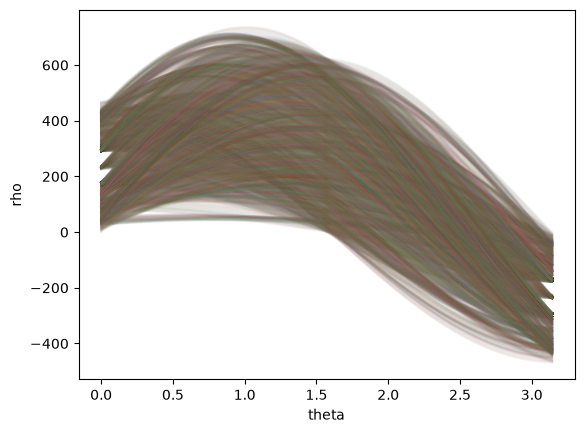

In [9]:
y_axis, x_axis = np.nonzero(edges)
thetas_plot = np.linspace(0, np.pi, 180)
rho_all = x_axis[:, None] * np.cos(thetas_plot) + y_axis[:, None] * np.sin(thetas_plot)   # (N, 180)
plt.plot(thetas_plot, rho_all.T, alpha=0.02)
plt.xlabel("theta"); plt.ylabel("rho"); plt.show()

# Accumulator (vote matrix)
Giữ tham số cũ: `THETA_STEP = pi/100`, `DISTANCE_STEP = 2`.  
Sửa so với bản cũ: rho chạy từ `-diag` đến `+diag` (bản cũ chỉ từ 0 nên mất mọi đường có rho < 0), và **làm tròn** vào ô gần nhất thay vì so sánh `==` (bản cũ chỉ khớp các rho chẵn nên mất ~một nửa phiếu).

(784, 100) 626


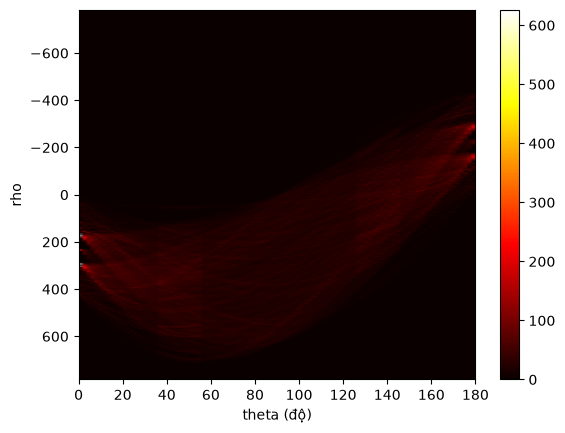

In [10]:
THETA_STEP = np.pi / 100
DISTANCE_STEP = 2
DELTA_DEG = 10

diag = np.hypot(*img.shape[:2])
n_theta = int(round(np.pi / THETA_STEP))
n_rho = int(round(2 * diag / DISTANCE_STEP)) + 1

ACCUMULATOR, theta_range, distance_range = hough_accumulate(
    edges, (0, np.pi - THETA_STEP), (-diag, diag), n_theta, n_rho,
    grad_dir=grad_dir, delta_deg=DELTA_DEG)

print(ACCUMULATOR.shape, ACCUMULATOR.max())
plt.imshow(ACCUMULATOR, aspect="auto", cmap="hot",
           extent=[0, 180, distance_range[-1], distance_range[0]])
plt.xlabel("theta (độ)"); plt.ylabel("rho"); plt.colorbar(); plt.show()

## Tìm đỉnh (làm mượt bằng convolve2d + triệt phi cực đại)
Bản cũ lấy `ACCUMULATOR > 10` nên một đường thật sinh ra cả cụm đỉnh sát nhau; NMS chỉ giữ 1 đỉnh mỗi cụm.

In [11]:
sorted_top_peaks = find_peaks(ACCUMULATOR, n_peaks=10, nms_radius=3, smooth_sigma=1.0,
                              thetas=theta_range, rhos=distance_range)
for rho, theta, votes in sorted_top_peaks:
    print(f"rho={rho:8.2f}  theta={np.rad2deg(theta):6.2f}°  votes={votes:.0f}")

rho=  178.95  theta=  1.80°  votes=191
rho=  302.92  theta=  1.80°  votes=161
rho= -286.93  theta=176.40°  votes=103
rho= -154.96  theta=176.40°  votes=128
rho= -260.93  theta=174.60°  votes=136
rho= -142.96  theta=163.80°  votes=68
rho=  234.94  theta=  0.00°  votes=33
rho= -222.94  theta=171.00°  votes=99
rho=  346.91  theta=  7.20°  votes=74
rho= -240.94  theta=172.80°  votes=127


# Vẽ đường
Giữ cấu trúc `return_line` / `draw_lines` cũ, nhưng nhận trực tiếp `(rho, theta)`, độ dài đoạn lấy theo đường chéo ảnh (thay cho số cứng 1000), và đổi sang RGB khi hiển thị (bản cũ vẽ màu `(255,0,0)` trên ảnh BGR rồi `imshow` nên bị lệch màu).

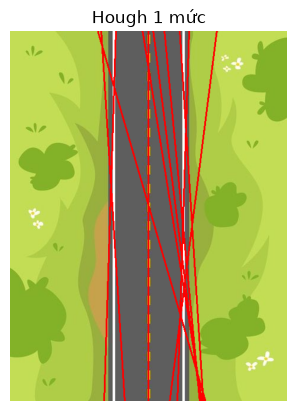

In [7]:
def return_line(lines_rt, length=None):
    length = length or int(np.hypot(*img.shape[:2]))
    out = []
    for rho, theta in lines_rt:
        a, b = np.cos(theta), np.sin(theta)
        x0, y0 = a * rho, b * rho
        p1 = (int(x0 - length * b), int(y0 + length * a))
        p2 = (int(x0 + length * b), int(y0 - length * a))
        out.append((p1, p2))
    return out

def draw_lines(image, lines_rt, color=(0, 0, 255), thickness=2):   # BGR: đỏ
    for p1, p2 in return_line(lines_rt):
        cv.line(image, p1, p2, color, thickness)
    return image

def show(image_bgr, title=""):
    plt.imshow(cv.cvtColor(image_bgr, cv.COLOR_BGR2RGB))
    plt.title(title); plt.axis("off"); plt.show()

show(draw_lines(img.copy(), [(r, t) for r, t, _ in sorted_top_peaks]), "Hough 1 mức")

# Method
## Method 1: Coarse to fine
Bản cũ trộn lẫn chỉ số và giá trị, dùng `CHILD_THETA = 2` (radian!), so sánh số thực bằng `==`, và không bỏ phiếu lại từ điểm cạnh. Bản mới: lưới thô -> quanh mỗi đỉnh bỏ phiếu lại từ chính các điểm cạnh với bước nhỏ hơn `refine_factor` lần.

rho= 177.954  theta=  0.000°
rho= 302.923  theta=  0.000°
rho=-290.927  theta=  0.000°
rho=-157.960  theta=  0.000°
rho=-258.183  theta=174.375°
rho=-146.963  theta=166.725°
rho= 236.940  theta=  0.000°
rho=-222.693  theta=171.000°
rho= 346.161  theta=  4.500°
rho=-243.688  theta=173.025°


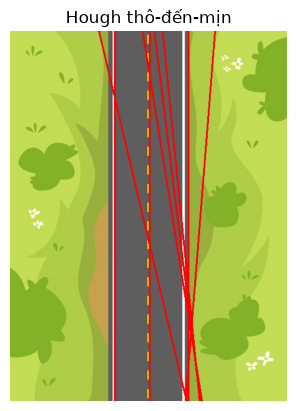

In [8]:
lines_ms = hough_multiscale(
    edges, grad_dir, n_levels=2, refine_factor=8, n_lines=10,
    delta_deg=DELTA_DEG,
    coarse_theta_step_deg=np.rad2deg(THETA_STEP), coarse_rho_step=DISTANCE_STEP)

for rho, theta in lines_ms:
    print(f"rho={rho:8.3f}  theta={np.rad2deg(theta):7.3f}°")
show(draw_lines(img.copy(), lines_ms), "Hough thô-đến-mịn")